<a href="https://colab.research.google.com/github/Dnaglitch/orca-call-detector/blob/main/Orca_Call_Categorizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR-USERNAME/orca-call-detector/blob/main/notebooks/01_baseline_training.ipynb)

# Import Libraries

In [ ]:
!pip install -q awscli librosa
import os, tarfile, random, json
import numpy as np
import pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import tarfile
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 14.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


# Training
> Reads the data labels from AWS, downloads the data (~260 mb)



In [ ]:
!aws s3 ls --no-sign-request s3://acoustic-sandbox/labeled-data/detection/train/

2019-09-26 18:38:23          0 
2019-11-18 04:57:42  258821972 OrcasoundLab07052019_PodCastRound2.tar.gz
2020-04-02 04:15:54  417794549 OrcasoundLab09272017_PodCastRound3.tar.gz
2020-10-25 07:25:38 1075749718 TestDataLatest_PodCastAllRounds_123.tar.gz
2020-09-12 07:01:40 2134169900 TrainDataLatest_PodCastAllRounds.tar.gz
2020-09-20 22:03:50 3501009623 TrainDataLatest_PodCastAllRounds_123567.tar.gz
2020-10-25 07:25:38 5461870195 TrainDataLatest_PodCastAllRounds_123567910.tar.gz
2019-11-18 05:00:17 1731393480 WHOIS09222019_PodCastRound1.tar.gz
2020-08-22 10:06:44      41904 podcast2.tsv
2020-08-22 10:07:20      57755 podcast3.tsv
2020-08-22 10:08:15      12970 test.tsv


In [3]:
import subprocess

def s3ls(prefix):
    r = subprocess.run( ["aws", "s3", "ls", "--no-sign-request", prefix], capture_output=True, text=True)
    print(f"--- {prefix}")
    print(r.stdout or "(empty)")
    if r.stderr:
        print("STDERR:", r.stderr)

s3ls("s3://acoustic-sandbox/")
s3ls("s3://acoustic-sandbox/labeled-data/")
s3ls("s3://acoustic-sandbox/labeled-data/detection/")
s3ls("s3://acoustic-sandbox/labeled-data/detection/train/")


--- s3://acoustic-sandbox/
                           PRE 2017-09-05-SRKW-highlight-hour/
                           PRE 2017-09-05-SRKW/
                           PRE 2017-09-27-OS-continuous-wavs/
                           PRE 2017-09-27_OS_SRKW-wav/
                           PRE 2017_8_VesselsAndWavS/
                           PRE 2018-sperm-whale-Yukusam/
                           PRE 2019-11-14_PT_SRKW_HLS/
                           PRE 2019-Orcasound-examples/
                           PRE 2020-06-26-SRKW-Lpod/
                           PRE 2021_9_12_OS_YearsBestVocalPassby/
                           PRE OS_AIS/
                           PRE acoustic-separation/
                           PRE ambient-sound-analysis/
                           PRE clap-model/
                           PRE data-audio-raw/
                           PRE fest-content/
                           PRE festtest/
                           PRE go-test/
                           PRE humpbacks/


In [4]:
import os, subprocess

ARCHIVE = "OrcasoundLab07052019_PodCastRound2.tar.gz"
S3_URI  = f"s3://acoustic-sandbox/labeled-data/detection/train/{ARCHIVE}"

if not os.path.exists(ARCHIVE):
    r = subprocess.run(["aws", "s3", "cp", "--no-sign-request", S3_URI, "."],
                       capture_output=True, text=True)
    print("exit code:", r.returncode)
    print(r.stdout[-1500:]); print(r.stderr[-1500:])

print("Downloaded =", os.path.exists(ARCHIVE), os.path.getsize(ARCHIVE) if os.path.exists(ARCHIVE) else 0, "MB")

exit code: 0
(127.9 MiB/s) with 1 file(s) remaining
Completed 242.5 MiB/246.8 MiB (127.9 MiB/s) with 1 file(s) remaining
Completed 242.8 MiB/246.8 MiB (128.0 MiB/s) with 1 file(s) remaining
Completed 243.0 MiB/246.8 MiB (127.7 MiB/s) with 1 file(s) remaining
Completed 243.2 MiB/246.8 MiB (127.7 MiB/s) with 1 file(s) remaining
Completed 243.5 MiB/246.8 MiB (127.8 MiB/s) with 1 file(s) remaining
Completed 243.8 MiB/246.8 MiB (127.2 MiB/s) with 1 file(s) remaining
Completed 244.0 MiB/246.8 MiB (127.3 MiB/s) with 1 file(s) remaining
Completed 244.2 MiB/246.8 MiB (127.3 MiB/s) with 1 file(s) remaining
Completed 244.5 MiB/246.8 MiB (127.4 MiB/s) with 1 file(s) remaining
Completed 244.8 MiB/246.8 MiB (127.4 MiB/s) with 1 file(s) remaining
Completed 245.0 MiB/246.8 MiB (127.5 MiB/s) with 1 file(s) remaining
Completed 245.2 MiB/246.8 MiB (127.5 MiB/s) with 1 file(s) remaining
Completed 245.5 MiB/246.8 MiB (127.5 MiB/s) with 1 file(s) remaining
Completed 245.8 MiB/246.8 MiB (127.6 MiB/s) with 1 

Check wav file names, find train and read the README

In [5]:
import tarfile

with tarfile.open(ARCHIVE) as t:
    names = t.getnames()
    print("entries:", len(names))
    print("\n".join(names[:20]))
    t.extractall(".")

print("\ntop level:", os.listdir("."))

entries: 64
Round2_OS_07_05
Round2_OS_07_05/dev.tsv
Round2_OS_07_05/invstd64.txt
Round2_OS_07_05/mean64.txt
Round2_OS_07_05/README.md
Round2_OS_07_05/train.tsv
Round2_OS_07_05/wav
Round2_OS_07_05/wav/1562337136_0004.wav
Round2_OS_07_05/wav/1562337136_0005.wav
Round2_OS_07_05/wav/1562337136_0006.wav
Round2_OS_07_05/wav/1562337136_000a.wav
Round2_OS_07_05/wav/1562337136_000b.wav
Round2_OS_07_05/wav/1562337136_000c.wav
Round2_OS_07_05/wav/1562337136_000d.wav
Round2_OS_07_05/wav/1562337136_000e.wav
Round2_OS_07_05/wav/1562337136_0010.wav
Round2_OS_07_05/wav/1562337136_0012.wav
Round2_OS_07_05/wav/1562337136_0013.wav
Round2_OS_07_05/wav/1562337136_0017.wav
Round2_OS_07_05/wav/1562337136_0018.wav


/tmp/ipykernel_6037/200884247.py:7: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(".")



top level: ['.config', 'Round2_OS_07_05', 'OrcasoundLab07052019_PodCastRound2.tar.gz', 'sample_data']


In [6]:
import os, pandas as pd

BASE = "Round2_OS_07_05"
TSV_TRAIN = os.path.join(BASE, "train.tsv")
TSV_DEV   = os.path.join(BASE, "dev.tsv")
WAV_DIR   = os.path.join(BASE, "wav")

print(open(os.path.join(BASE, "README.md")).read())
print("wav files:", len([f for f in os.listdir(WAV_DIR) if f.endswith(".wav")]))

# Dataset format:

Standard dataset format understood by the `AudioFileDataset` class consists of:
* A train/dev TSV file containing at minimum, columns: `(wav_filename, start_time_s, duration_s)`
* A directory containing all the wav files pointed to by `wav_filename` 
* Precomputed mean, invstd .txt files for 64dim mel filterbank features used by the current classifier version on Pod.Cast (see src.params for details)

The TSV file only contains entries for the positive segments in a given `wav_filename`. All the remaining segments in each `wav_filename` are automatically split up into windows assumed as negative by the `AudioFileDataset` class. 
* If you think there's not enough recall in the labels for a wav file, better to chop up and keep only the positive segments as separate wav files. 
* For wavfiles containing only negative examples, the TSV has a single entry of tiny duration (0/0.01s). `AudioFileDataset` will automatically ignore this as it's too small and process the rest of

In [7]:
tr = pd.read_csv(TSV_TRAIN, sep="\t")
dv = pd.read_csv(TSV_DEV,   sep="\t")

print("train rows:", tr.shape, "| dev rows:", dv.shape)
print(tr.columns.tolist())
display(tr.head())

print("\nzero-duration (all-negative) markers:", (tr["duration_s"] == 0).sum())
print("unique wavs in train:", tr["wav_filename"].nunique())
print("unique wavs in dev:", dv["wav_filename"].nunique())

# critical check: no file should appear in both
overlap = set(tr["wav_filename"]) & set(dv["wav_filename"])
print("files in both:", len(overlap))

train rows: (357, 7) | dev rows: (89, 7)
['wav_filename', 'start_time_s', 'duration_s', 'location', 'date', 'data_source', 'data_source_id']


,wav_filename,start_time_s,duration_s,location,date,data_source,data_source_id
0,1562337136_0004.wav,49.765625,2.450000,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136
1,1562337136_0004.wav,41.046007,1.658854,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136
2,1562337136_0004.wav,37.345486,1.743924,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136
3,1562337136_0004.wav,42.917535,2.594618,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136
4,1562337136_0004.wav,45.980035,2.041667,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136



zero-duration (all-negative) markers: 0
unique wavs in train: 50
unique wavs in dev: 7
files in both: 0


In [8]:
import numpy as np, librosa

SR, WIN_S, HOP_S, MIN_OVL = 16000, 2.45, 1.0, 0.4
TARGET_FRAMES = 77

def melspec(y, sr=SR, n_mels=64):
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024, hop_length=512,
                                       n_mels=n_mels, fmin=50, fmax=8000)
    return librosa.power_to_db(S, ref=np.max)

def overlap(a0, a1, b0, b1):
    return max(0.0, min(a1, b1) - max(a0, b0))

def build(df, wav_dir, max_files=None):
    calls = {fn: [(r.start_time_s, r.start_time_s + r.duration_s)
                  for r in g.itertuples() if r.duration_s > 0]
             for fn, g in df.groupby("wav_filename")}

    files = [f for f in sorted(calls) if os.path.exists(os.path.join(wav_dir, f))]
    if max_files: files = files[:max_files]

    X, y, src = [], [], []
    for fn in files:
        audio, _ = librosa.load(os.path.join(wav_dir, fn), sr=SR)
        dur, ivs = len(audio) / SR, calls[fn]
        t = 0.0
        while t + WIN_S <= dur:
            ov = max([overlap(t, t + WIN_S, c0, c1) for c0, c1 in ivs], default=0.0)
            if   ov >= MIN_OVL: label = 1
            elif ov == 0.0:     label = 0
            else:               t += HOP_S; continue

            S = melspec(audio[int(t*SR):int((t+WIN_S)*SR)])
            if S.shape[1] < TARGET_FRAMES:
                S = np.pad(S, ((0,0),(0,TARGET_FRAMES-S.shape[1])), constant_values=S.min())
            X.append(S[:, :TARGET_FRAMES]); y.append(label); src.append(fn)
            t += HOP_S

    return (np.array(X, np.float32), np.array(y, np.float32), np.array(src))

X_tr_raw, y_tr_raw, src_tr = build(tr, WAV_DIR)
X_va_raw, y_va_raw, src_va = build(dv, WAV_DIR)

print("train:", X_tr_raw.shape, "pos:", int(y_tr_raw.sum()), "neg:", int((y_tr_raw==0).sum()))
print("dev:  ", X_va_raw.shape, "pos:", int(y_va_raw.sum()), "neg:", int((y_va_raw==0).sum()))

train: (2845, 64, 77) pos: 1101 neg: 1744
dev:   (388, 64, 77) pos: 215 neg: 173


Visualize the spectograms to check if model should be able to tell a difference and check the data's accuracy

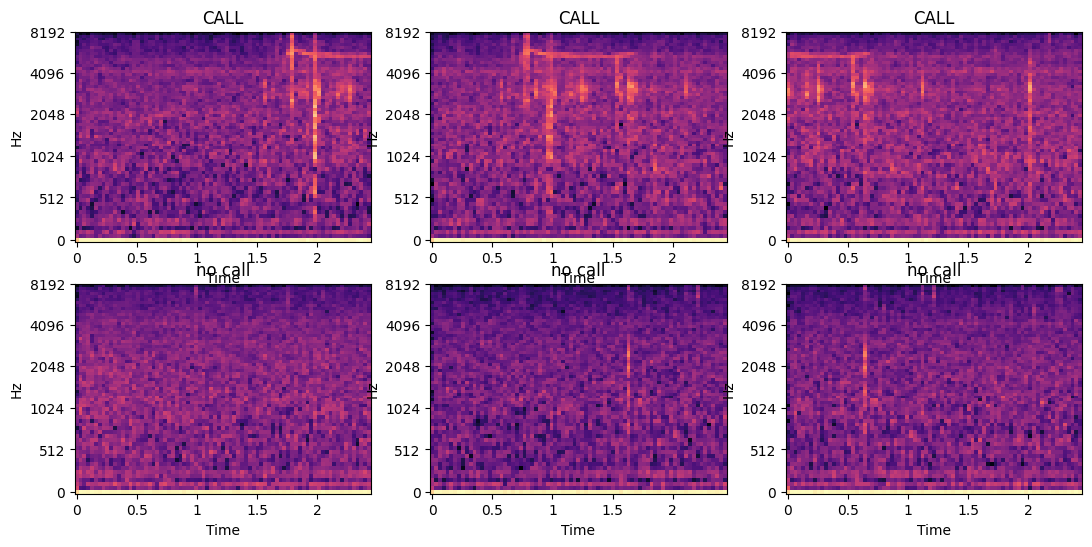

In [13]:
import matplotlib.pyplot as plt, librosa.display
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, i in zip(axes[0], np.where(y_tr_raw==1)[0][:3]):
    librosa.display.specshow(X_tr_raw[i], sr=SR, hop_length=512,
                             x_axis="time", y_axis="mel", ax=ax); ax.set_title("CALL")
for ax, i in zip(axes[1], np.where(y_tr_raw==0)[0][:3]):
    librosa.display.specshow(X_tr_raw[i], sr=SR, hop_length=512,
                             x_axis="time", y_axis="mel", ax=ax); ax.set_title("no call")
plt.show()

In [14]:
def prep(a): #Normalize the training decibal values -- Usually from -80 to 0, but the model doesn't train well, so normalize from 0-1
 return ((a + 80.0)/80.0)[..., np.newaxis] #Add new axis to prevent fitting error w/keras
X_tr, y_tr = prep(X_tr_raw), y_tr_raw
X_va, y_va = prep(X_va_raw), y_va_raw
print(X_tr.shape, X_va.shape)

(2845, 64, 77, 1) (388, 64, 77, 1)


# Model Buliding, Training, Testing, Saving the model


>Saves the model and configures future inputted data to be normalized from 0-1 instead of the raw -80 to 0 decibal values





Building the model

In [15]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=X_tr.shape[1:]),

    layers.Conv2D(16, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 77, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 38, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 38, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 19, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 19, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 9, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,521 (107.50 KB)

 Trainable params: 27,521 (107.50 KB)

 Non-trainable params: 0 (0.00 B)

Train model -- 40 epochs

In [16]:
early = keras.callbacks.EarlyStopping( #Keep best model and stop training after improvement plateau
    monitor="val_auc", mode="max",
    patience=6, restore_best_weights=True,
)

hist = model.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=40, batch_size=32,
    callbacks=[early], verbose=1,
)

Epoch 1/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 117ms/step - accuracy: 0.6130 - auc: 0.5067 - loss: 0.6697 - val_accuracy: 0.4459 - val_auc: 0.6843 - val_loss: 0.7253
Epoch 2/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.6130 - auc: 0.5081 - loss: 0.6693 - val_accuracy: 0.4459 - val_auc: 0.6813 - val_loss: 0.7408
Epoch 3/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - accuracy: 0.6130 - auc: 0.5226 - loss: 0.6668 - val_accuracy: 0.4459 - val_auc: 0.6898 - val_loss: 0.7450
Epoch 4/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - accuracy: 0.6130 - auc: 0.5453 - loss: 0.6644 - val_accuracy: 0.4459 - val_auc: 0.6981 - val_loss: 0.7374
Epoch 5/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - accuracy: 0.6130 - auc: 0.5652 - loss: 0.6622 - val_accuracy: 0.4459 - val_auc: 0.6909 - val_loss: 0.7414
Epoch 6/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 11s 124ms/step - accuracy: 0.6130 - auc: 0.5725 - loss: 0.6596 - val_accuracy: 0.4459 - val_auc: 0.6944 - val_loss: 0.7384
Epoch 7/40
89/89 ━━━━━━━━━━━━━━━━━━━

Model Testing

Validation AUC: 0.705

Confusion matrix  [rows: true, cols: predicted]
            no call  call
no call     [172   1]
call        [180  35]

              precision    recall  f1-score   support

     no call       0.49      0.99      0.66       173
        call       0.97      0.16      0.28       215

    accuracy                           0.53       388
   macro avg       0.73      0.58      0.47       388
weighted avg       0.76      0.53      0.45       388



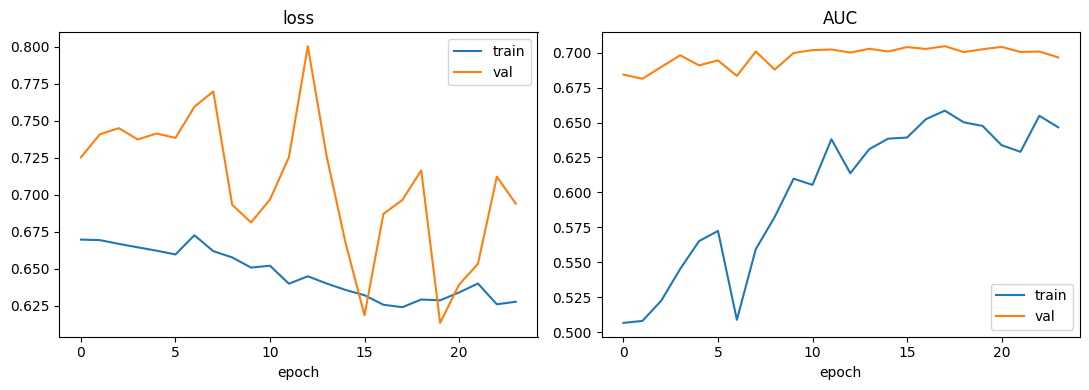

In [17]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

p = model.predict(X_va, verbose=0).ravel() #Convert to 1d array
pred = (p >= 0.5).astype(int)

print("Validation AUC:", round(roc_auc_score(y_va, p), 3))
print()
print("Confusion matrix  [rows: true, cols: predicted]")
print("            no call  call")
cm = confusion_matrix(y_va, pred)
print("no call    ", cm[0])
print("call       ", cm[1])
print()
print(classification_report(y_va, pred, target_names=["no call", "call"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train")
ax[0].plot(hist.history["val_loss"], label="val")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train")
ax[1].plot(hist.history["val_auc"], label="val")
ax[1].set_title("AUC"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [18]:
print("Fill these into README.md and index.html:")
print("  Validation AUC:", round(roc_auc_score(y_va, p), 3))
print("  Recall (calls found):", round(cm[1][1] / cm[1].sum(), 3))
print("  Precision:", round(cm[1][1] / (cm[0][1] + cm[1][1]), 3))
print("  Training windows:", len(X_tr), "| Dev windows:", len(X_va))

Fill these into README.md and index.html:
  Validation AUC: 0.705
  Recall (calls found): 0.163
  Precision: 0.972
  Training windows: 2845 | Dev windows: 388


In [21]:
import json

model.save("orca_detector.keras")

config = {
    "sr": SR,
    "win_s": WIN_S,
    "n_mels": 64,
    "target_frames": TARGET_FRAMES,
    "hop_length": 512,
    "fmin": 50,
    "fmax": 8000,
}
with open("model_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(json.dumps(config, indent=2))

from google.colab import files
files.download("orca_detector.keras")
files.download("model_config.json")

{
  "sr": 16000,
  "win_s": 2.45,
  "n_mels": 64,
  "target_frames": 77,
  "hop_length": 512,
  "fmin": 50,
  "fmax": 8000
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>